# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [3]:
# TODO 1: one 1080p RGB frame, in MB
frame_mb = 1920 * 1080 * 3 / 1_000_000

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 60 * 60 * 24

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
fleet_tb = 400 * frames_per_day * 1920 * 1080 * 3 / 1_000_000_000_000

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
fleet_tb_small = 400 * (10 * 60 * 60 * 24) * 640 * 360 * 3 / 1_000_000_000_000
pct_pixels_remaining = (640 * 360) / (1920 * 1080) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 6.22 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 6,449.7 TB/day | Fleet (360p, 10 fps): 238.9 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37, name one spatial and one temporal piece of evidence the security team could lose.

**Your answer:** Spatially, a face or licence-plate number may become too small to identify after downsampling.
Temporally, 10 fps can miss a quick movement or make the exact order of two actions unclear.
Interpolation can smooth the result, but it cannot recreate details that were never recorded.


## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

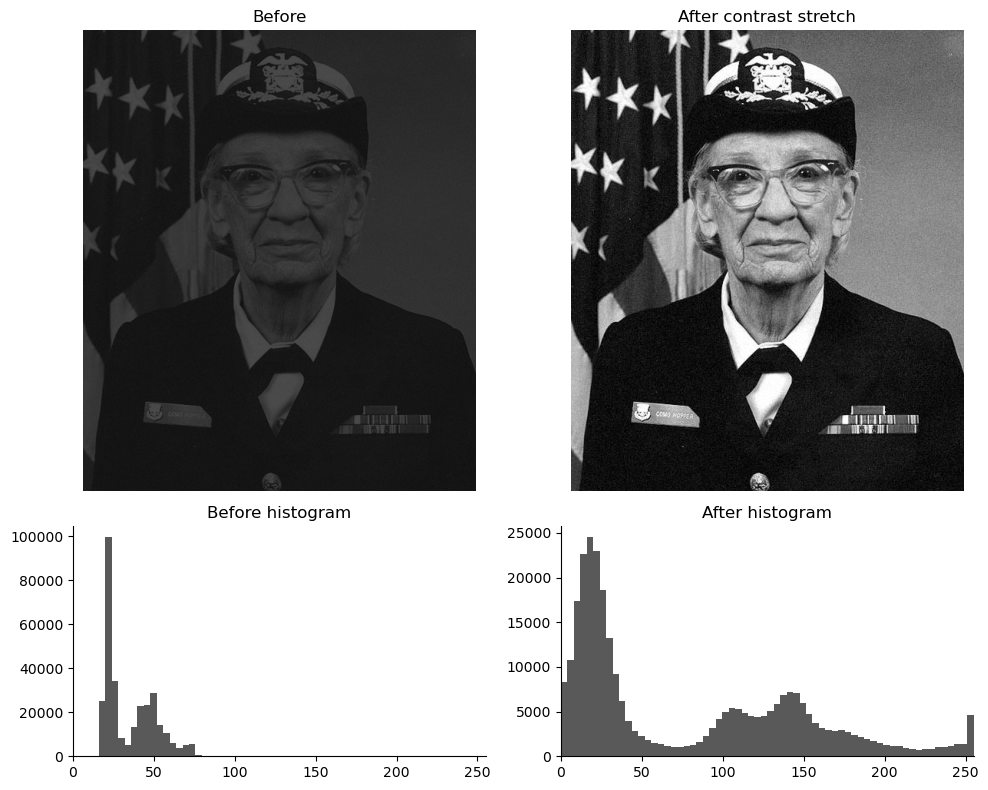

Contrast before: 0.609  ->  after: 1.000


In [4]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
p1, p99 = np.percentile(night_still, [1, 99])
c_before = michelson(p99, p1)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip((night_still - p1) / (p99 - p1) * 255, 0, 255)

c_after = michelson(*np.percentile(stretched, [99, 1]))

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Before"); axes[0, 0].axis("off")
axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("After contrast stretch"); axes[0, 1].axis("off")
axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color="0.35")
axes[1, 0].set_title("Before histogram"); axes[1, 0].set_xlim(0, 255)
axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color="0.35")
axes[1, 1].set_title("After histogram"); axes[1, 1].set_xlim(0, 255)


plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the shape of the night image's histogram and explain why stretching helped.

**Your answer:** The histogram is narrow and concentrated toward the dark side, showing low brightness and low contrast.
Stretching spreads the existing values across 0–255, so objects become easier to see without adding new information.
A histogram only counts brightness values; it does not show where those values occur or what objects are present.


## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

standing: 68.7-78.1 s
running: 78.6-86.0 s


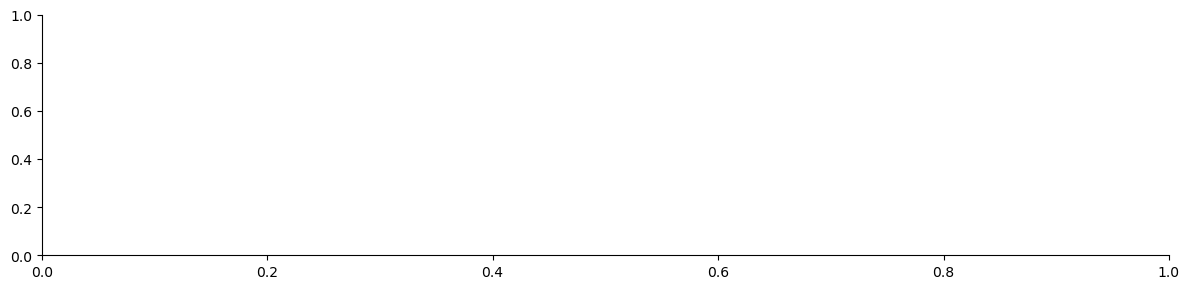

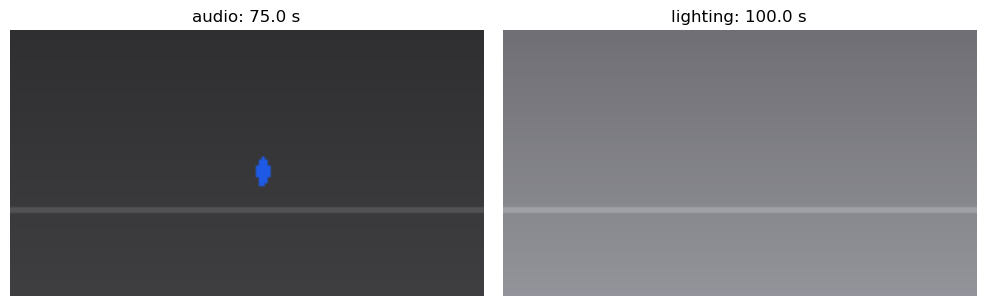

In [5]:
# TODO 1: person speed (px/s)
dx = cctv.person_x.diff(FPS)
dy = cctv.person_y.diff(FPS)
speed = np.sqrt(dx**2 + dy**2)

# TODO 2: standing / running time ranges (print the first and last time of each)
for label, mask in [("standing", speed < 3), ("running", speed > 25)]:
    times = cctv.loc[mask, "time_s"]
    if len(times):
        print(f"{label}: {times.iloc[0]:.1f}-{times.iloc[-1]:.1f} s")
    else:
        print(f"{label}: no frames detected")

# TODO 3: event frame indices
audio_candidates = np.flatnonzero(cctv.audio_level_db.to_numpy() > -20)
audio_event_idx = int(audio_candidates[0]) if len(audio_candidates) else None
brightness_jump = cctv.mean_brightness.diff().to_numpy()
lighting_candidates = np.flatnonzero(brightness_jump > 40)
lighting_event_idx = int(lighting_candidates[0]) if len(lighting_candidates) else None

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))

plt.tight_layout(); plt.show()

ax.plot(cctv.time_s, cctv.motion_energy, color="#4C72B0", lw=0.8)
events = [(audio_event_idx, "audio", "#D9534F"), (lighting_event_idx, "lighting", "#F0AD4E")]
for idx, label, color in events:
    if idx is not None:
        t_event = cctv.time_s.iloc[idx]
        ax.axvline(t_event, color=color, lw=1.5, label=f"{label} ({t_event:.1f}s)")
ax.set_xlabel("Time (s)"); ax.set_ylabel("Motion energy")
ax.set_title("Motion timeline with detected events"); ax.legend()
# TODO 5: one keyframe per event
keyframes = [(idx, label) for idx, label, _ in events if idx is not None]
if keyframes:
    fig, frame_axes = plt.subplots(1, len(keyframes), figsize=(5 * len(keyframes), 3), squeeze=False)
    for ax_frame, (idx, label) in zip(frame_axes[0], keyframes):
        ax_frame.imshow(render_frame(cctv.iloc[idx]))
        ax_frame.set_title(f"{label}: {cctv.time_s.iloc[idx]:.1f} s"); ax_frame.axis("off")
    plt.tight_layout(); plt.show()

**Reflection:** If uniform keyframes were used, which events could be missed?

**Your answer:** Frames every 20 seconds could miss the short sound around 75 seconds and the sudden lighting change.
They might also miss the exact moment when the person starts running.
Content-based keyframes are better because they choose frames around meaningful changes or events.


## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

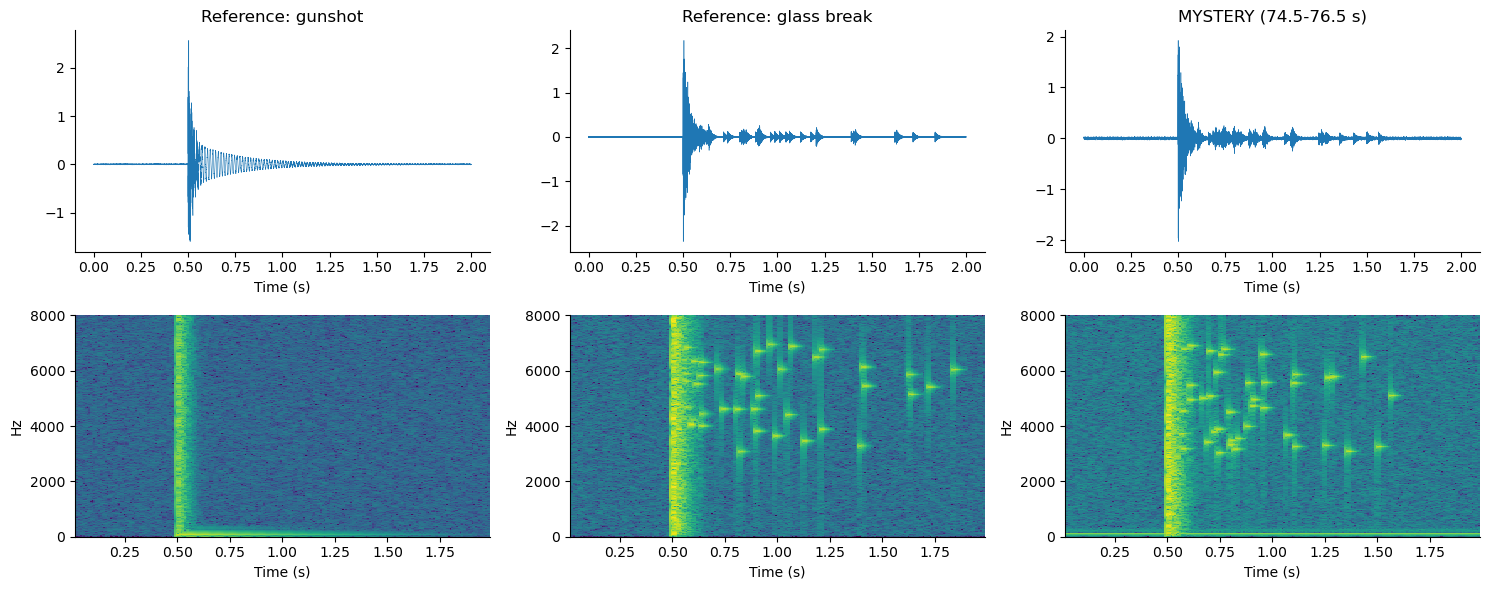

{'Reference: gunshot': 0.21536812880335363, 'Reference: glass break': 0.6377676959141663, 'MYSTERY (74.5-76.5 s)': 0.6562646133216413}
Verdict: the mystery sound is most consistent with breaking glass.


In [6]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
for col, (name, clip) in enumerate(clips.items()):
    t_clip = np.arange(len(clip)) / FS
    axes[0, col].plot(t_clip, clip, lw=0.4)
    axes[0, col].set_title(name); axes[0, col].set_xlabel("Time (s)")
    f, t_spec, sxx = signal.spectrogram(clip, fs=FS, nperseg=512, noverlap=384)
    axes[1, col].pcolormesh(t_spec, f, 10 * np.log10(sxx + 1e-12), shading="auto")
    axes[1, col].set_ylim(0, 8000); axes[1, col].set_xlabel("Time (s)"); axes[1, col].set_ylabel("Hz")


plt.tight_layout(); plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
hf_fraction = {}
for name, clip in clips.items():
    f, t_spec, sxx = signal.spectrogram(clip, fs=FS, nperseg=512, noverlap=384)
    window = (t_spec >= 0.2) & (t_spec <= 1.2)
    total = sxx[:, window].sum()
    hf_fraction[name] = float(sxx[(f > 3000), :][:, window].sum() / total)

print(hf_fraction)
# TODO 4: verdict
mystery_fraction = hf_fraction["MYSTERY (74.5-76.5 s)"]
glass_fraction = hf_fraction["Reference: glass break"]
gunshot_fraction = hf_fraction["Reference: gunshot"]
verdict = "breaking glass" if abs(mystery_fraction - glass_fraction) < abs(mystery_fraction - gunshot_fraction) else "gunshot"
print(f"Verdict: the mystery sound is most consistent with {verdict}.")

**Reflection:** Could waveforms alone distinguish the sounds, and what does a spectrogram add?

**Your answer:** No. Both sounds have a sharp impact in their waveform, so they look similar in time.
A spectrogram adds time, frequency, and sound strength in one view.
The scattered high-frequency specks after the impact matched the glass reference, so the mystery sound was breaking glass.


## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

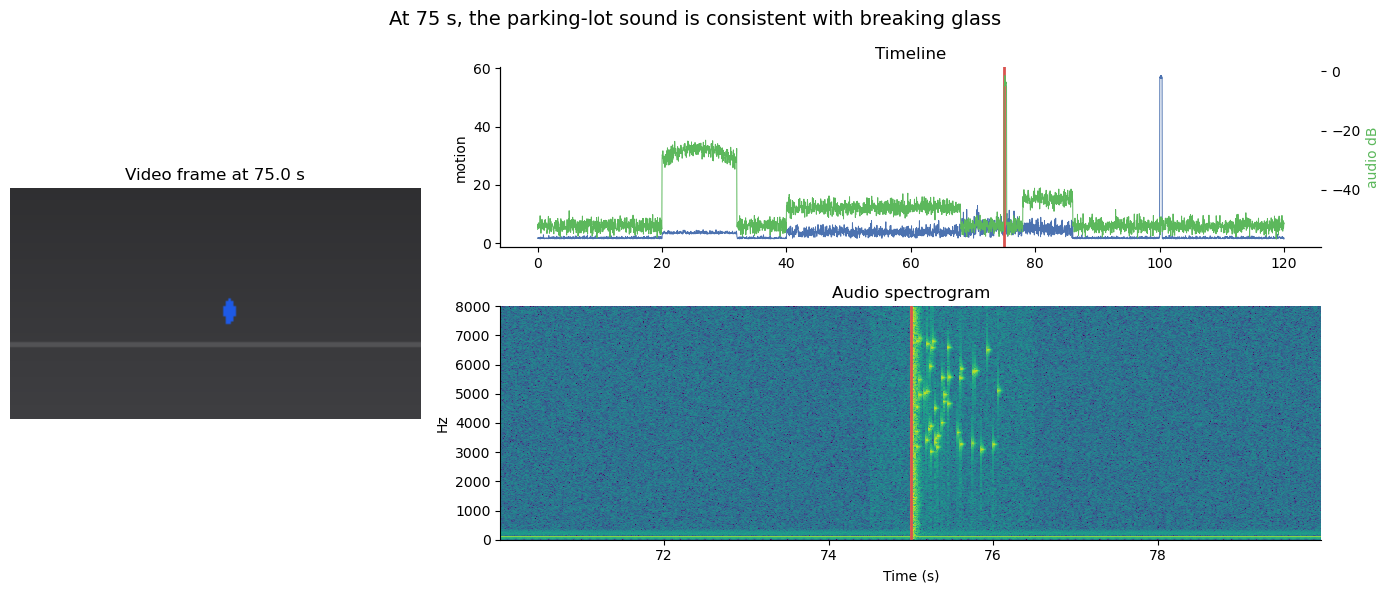

In [7]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
# TODO 1-4
frame_idx = int(np.abs(cctv.time_s - t_sel).argmin())
ax_frame = fig.add_subplot(gs[:, 0])
ax_frame.imshow(render_frame(cctv.iloc[frame_idx])); ax_frame.axis("off")
ax_frame.set_title(f"Video frame at {cctv.time_s.iloc[frame_idx]:.1f} s")
ax_t = fig.add_subplot(gs[0, 1])
ax_t.plot(cctv.time_s, cctv.motion_energy, color="#4C72B0", lw=0.7, label="motion")
ax_t2 = ax_t.twinx(); ax_t2.plot(cctv.time_s, cctv.audio_level_db, color="#5cb85c", lw=0.7, label="audio")
ax_t.axvline(t_sel, color="#D9534F", lw=2); ax_t.set_title("Timeline")
ax_t.set_ylabel("motion"); ax_t2.set_ylabel("audio dB", color="#5cb85c")
ax_s = fig.add_subplot(gs[1, 1])
audio_window = (t_audio >= 70) & (t_audio < 80)
f_sel, t_sel_spec, sxx_sel = signal.spectrogram(x_audio[audio_window], fs=FS, nperseg=512, noverlap=384)
ax_s.pcolormesh(70 + t_sel_spec, f_sel, 10 * np.log10(sxx_sel + 1e-12), shading="auto")
ax_s.set_ylim(0, 8000); ax_s.axvline(t_sel, color="#D9534F", lw=2)
ax_s.set_xlabel("Time (s)"); ax_s.set_ylabel("Hz"); ax_s.set_title("Audio spectrogram")
fig.suptitle("At 75 s, the parking-lot sound is consistent with breaking glass", fontsize=14)


plt.tight_layout(); plt.show()

**Reflection:** What if the audio track were offset by +2 seconds?

**Your answer:** The sound would appear two seconds after the real event and could be matched to the wrong movement or light change.
This would make the briefing tell the wrong story about what happened.
The synchronized timeline and spectrogram panel would reveal the error because the audio peak would not line up with the video event.


## Task 6 — The Decision (No Code)

**Your final briefing:** The person was standing for much of the 68.7–78.1 second period, and the mystery sound occurred from about 74.5–76.5 seconds and was most likely breaking glass.
I would show the synchronized timeline first because it connects motion, keyframes, and audio in one event-focused view.
For normal storage, 640 × 360 at 10 fps is practical, but incident footage should be saved at higher quality.
The policy must not sacrifice faces and licence plates, because those details may be needed for identification.


In [8]:
import os, base64
import matplotlib.pyplot as plt
from pathlib import Path

OUT = Path("pbi_exports"); OUT.mkdir(exist_ok=True)

# ---------- Task 1: storage ----------
frame_mb  = 1920*1080*3/1_000_000
fpd_1080  = 30*60*60*24
fleet_1080_tb = 400*fpd_1080*1920*1080*3/1_000_000_000_000
fleet_360_tb  = 400*(10*60*60*24)*640*360*3/1_000_000_000_000
pct_pix  = (640*360)/(1920*1080)*100

pd.DataFrame([
    {"scenario":"1080p @ 30 fps","frame_mb":frame_mb,"frames_per_day":fpd_1080,
     "fleet_tb":fleet_1080_tb,"pixels":1920*1080},
    {"scenario":"360p @ 10 fps","frame_mb":640*360*3/1_000_000,"frames_per_day":10*86400,
     "fleet_tb":fleet_360_tb,"pixels":640*360},
]).to_csv(OUT/"storage.csv", index=False)
pd.DataFrame([{"pct_pixels_remaining":pct_pix}]).to_csv(OUT/"pixels_remaining.csv", index=False)

# ---------- Task 3: timeline + events ----------
cctv.to_csv(OUT/"cctv.csv", index=False)
events = pd.DataFrame([
    {"event":"Standing",        "kind":"person_state","start_s":68.7,"end_s":78.1},
    {"event":"Running",         "kind":"person_state","start_s":78.6,"end_s":86.0},
    {"event":"Audio > -20 dB",  "kind":"audio",
     "start_s":float(cctv.time_s.iloc[audio_event_idx]),
     "end_s":  float(cctv.time_s.iloc[audio_event_idx])},
    {"event":"Brightness jump", "kind":"lighting",
     "start_s":float(cctv.time_s.iloc[lighting_event_idx]),
     "end_s":  float(cctv.time_s.iloc[lighting_event_idx])},
    {"event":"Mystery bang",    "kind":"audio","start_s":75.0,"end_s":75.0},
])
events.to_csv(OUT/"events.csv", index=False)

# ---------- Task 2 & 4 & 5: PNGs ----------
plt.imsave(OUT/"night_still.png",     night_still, cmap="gray", vmin=0, vmax=255)
plt.imsave(OUT/"night_stretched.png", stretched,  cmap="gray", vmin=0, vmax=255)

# render 75 s frame
i75 = int((cctv.time_s - 75).abs().idxmin())
plt.imsave(OUT/"frame_75s.png", render_frame(cctv.iloc[i75]))

# Task 4 spectrograms
for name, clip in clips.items():
    fig, ax = plt.subplots(figsize=(4,3))
    f_, t_, s_ = signal.spectrogram(clip, fs=FS, nperseg=512, noverlap=384)
    ax.pcolormesh(t_, f_, 10*np.log10(s_+1e-12), shading="auto")
    ax.set_ylim(0,8000); ax.set_title(name); ax.axis("off")
    fig.savefig(OUT/f"spec_{name.split(':')[0].strip().replace(' ','_')}.png", dpi=120, bbox_inches="tight")
    plt.close(fig)

# Task 4 feature table + verdict
pd.DataFrame([{"clip":k,"hf_fraction":v} for k,v in hf_fraction.items()])\
  .to_csv(OUT/"audio_features.csv", index=False)
pd.DataFrame([{"verdict":verdict,"mystery_hf":mystery_fraction,
               "glass_hf":glass_fraction,"gunshot_hf":gunshot_fraction,
               "mystery_time_s":75.0}]).to_csv(OUT/"verdict.csv", index=False)

# Task 2 histograms as PNGs
for name, arr in [("before",night_still),("after",stretched)]:
    fig, ax = plt.subplots(figsize=(4,2.5))
    ax.hist(arr.ravel(), bins=64, range=(0,255), color="0.35")
    ax.set_xlim(0,255); ax.set_title(f"{name} histogram"); ax.axis("off")
    fig.savefig(OUT/f"hist_{name}.png", dpi=120, bbox_inches="tight"); plt.close(fig)

print("Exported →", OUT.resolve())

Exported → C:\Users\vagee\OneDrive\Desktop\5th sem\VDUI\unit3handson\ppt1\pbi_exports
